### **Deep Learning Project: Handwritten Digit Classifier (MNIST)**
---



In [30]:
# Import necessary libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, classification_report


1. Dataset Loading

In [31]:
# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [32]:
# Display dataset shapes
print("Training Images Shape:", x_train.shape)
print("Training Labels Shape:", y_train.shape)

print("Testing Images Shape:", x_test.shape)
print("Testing Labels Shape:", y_test.shape)

Training Images Shape: (60000, 28, 28)
Training Labels Shape: (60000,)
Testing Images Shape: (10000, 28, 28)
Testing Labels Shape: (10000,)


In [33]:
# Display basic dataset information

print("Total Training Samples:", len(x_train))
print("Total Testing Samples:", len(x_test))
print("Image Dimensions:", x_train.shape[1:])
print("Number of Classes:", len(np.unique(y_train)))

# Display unique digit classes
print("Digit Classes:", np.unique(y_train))

Total Training Samples: 60000
Total Testing Samples: 10000
Image Dimensions: (28, 28)
Number of Classes: 10
Digit Classes: [0 1 2 3 4 5 6 7 8 9]


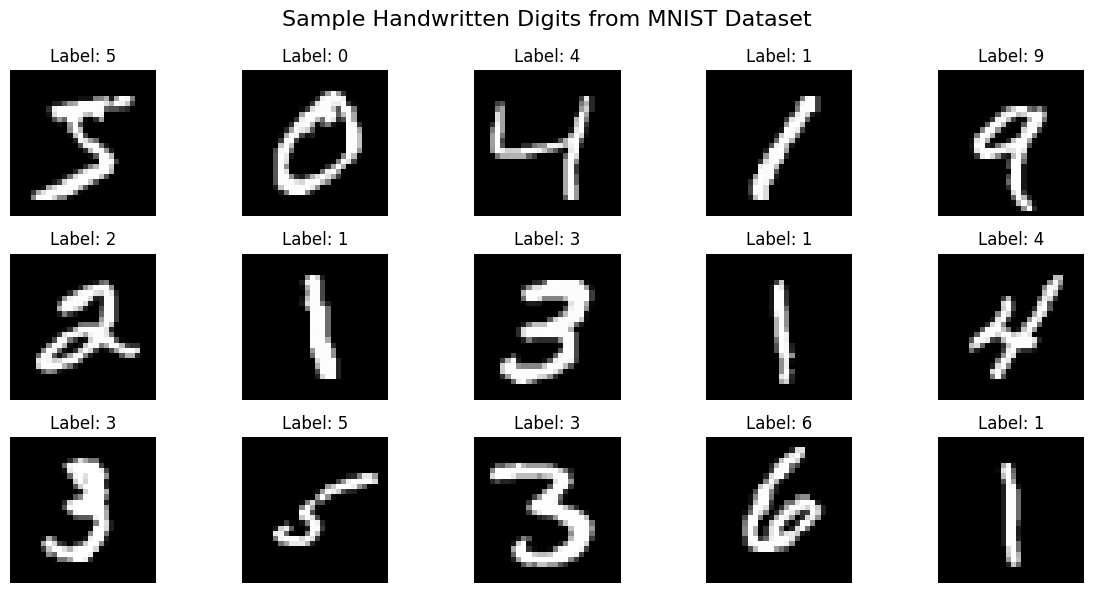

In [34]:
# Display sample handwritten digits

plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.suptitle("Sample Handwritten Digits from MNIST Dataset",
             fontsize=16)

plt.tight_layout()
plt.show()

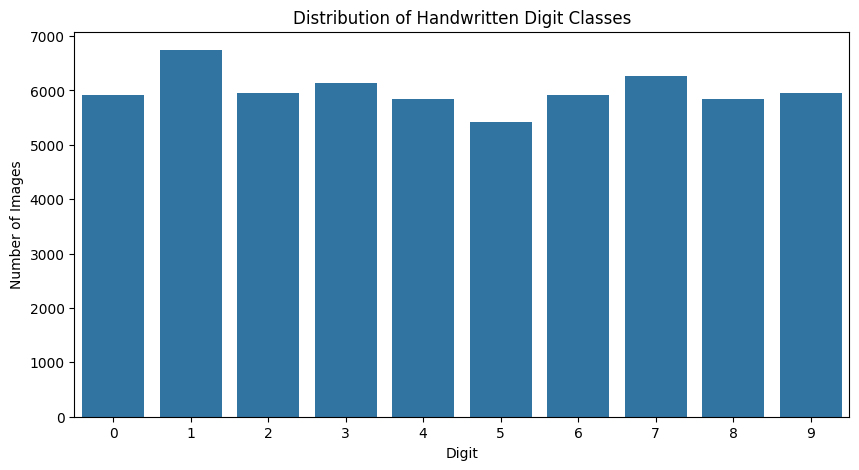

In [35]:
# Check the distribution of digit classes

plt.figure(figsize=(10, 5))

sns.countplot(x=y_train)

plt.title("Distribution of Handwritten Digit Classes")
plt.xlabel("Digit")
plt.ylabel("Number of Images")
plt.show()



In [36]:
# Print class counts
print(pd.Series(y_train).value_counts().sort_index())

0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64


2. Preprocessing

In [37]:
# Normalize pixel values
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Flatten images
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Display new shapes
print("Training Data Shepe After Flattening:", x_train.shape)
print("Tsting Data Shape After Flattening:", x_test.shape)

# Check normalized pixel values
print("Minimum Pixel Value:", x_train.min())
print("maximum Pixel Value:", x_train.max())

Training Data Shepe After Flattening: (60000, 784)
Tsting Data Shape After Flattening: (10000, 784)
Minimum Pixel Value: 0.0
maximum Pixel Value: 1.0


3. Model Architecture

In [38]:
# Build Deep Neural Network Model

model = Sequential([

    # Input Layer
    tf.keras.Input(shape=(784,)),

    # Hidden Layer 1
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    # Hidden Layer 2
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    # Hidden Layer 3
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),

    # Output Layer (10 classes: 0-9)
    Dense(10, activation='softmax')
])


In [39]:

# Display model architecture
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 244,554 (955.29 KB)

 Trainable params: 243,658 (951.79 KB)

 Non-trainable params: 896 (3.50 KB)

4. Training



In [40]:
# Compile the model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)



In [41]:
# Train the Deep Learning Model

history = model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.8692 - loss: 0.4368 - val_accuracy: 0.9549 - val_loss: 0.1474
Epoch 2/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9371 - loss: 0.2106 - val_accuracy: 0.9655 - val_loss: 0.1133
Epoch 3/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9514 - loss: 0.1623 - val_accuracy: 0.9676 - val_loss: 0.1056
Epoch 4/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.9576 - loss: 0.1393 - val_accuracy: 0.9732 - val_loss: 0.0909
Epoch 5/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9636 - loss: 0.1203 - val_accuracy: 0.9753 - val_loss: 0.0861
Epoch 6/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9662 - loss: 0.1086 - val_accuracy: 0.9753 - val_loss: 0.0886
Epoch 7/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9696 - loss: 0.1004 - val_accuracy: 0.9758 - val_loss: 0.0833
Epoch 8/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9723 - loss: 0.0893 - val_accur

5. Visualization



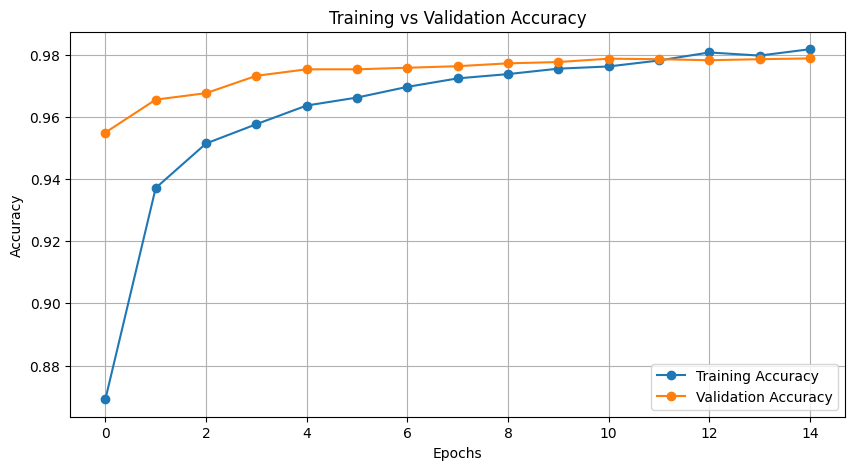

In [42]:
# Plot Training and Validation Accuracy

plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'],
         label='Training Accuracy',
         marker='o')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy',
         marker='o')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

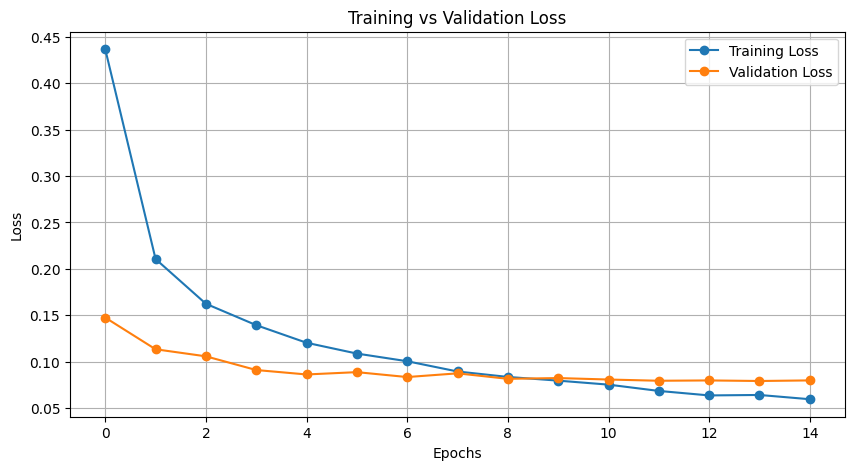

In [43]:
# Plot Training and Validation Loss

plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'],
         label='Training Loss',
         marker='o')

plt.plot(history.history['val_loss'],
         label='Validation Loss',
         marker='o')

plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

6. Evaluation



In [44]:
# Evaluate the model on unseen test data

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("test loss:", round(test_loss, 4))
print("test accuracy:", round(test_accuracy * 100, 2), "%")

test loss: 0.0731
test accuracy: 98.06 %


In [45]:
# Predict digits from test images

y_pred_prob = model.predict(x_test)

# Convert probabilities into predicted class labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Display actual vs predicted values
for i in range(10):
    print(f"Actual: {y_test[i]} | Predicted: {y_pred[i]}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Actual: 7 | Predicted: 7
Actual: 2 | Predicted: 2
Actual: 1 | Predicted: 1
Actual: 0 | Predicted: 0
Actual: 4 | Predicted: 4
Actual: 1 | Predicted: 1
Actual: 4 | Predicted: 4
Actual: 9 | Predicted: 9
Actual: 5 | Predicted: 5
Actual: 9 | Predicted: 9


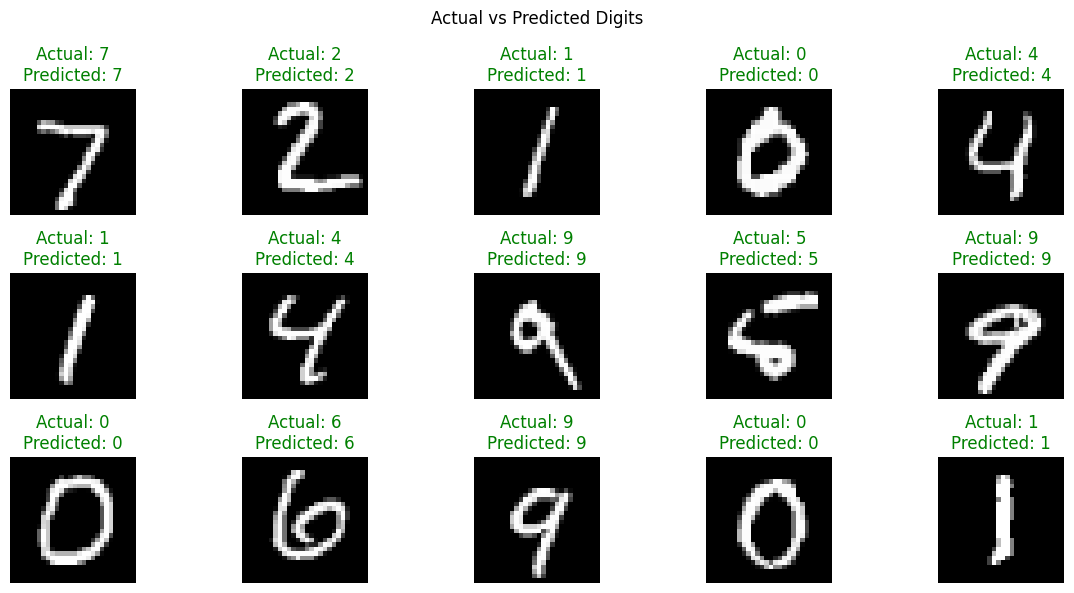

In [46]:
# Display actual and predicted digit images

plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(
        x_test[i].reshape(28, 28),
        cmap='gray'
    )

    color = 'green' if y_test[i] == y_pred[i] else 'red'

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}",
        color=color
    )

    plt.axis('off')

plt.suptitle("Actual vs Predicted Digits")
plt.tight_layout()
plt.show()

Confusion Matrix

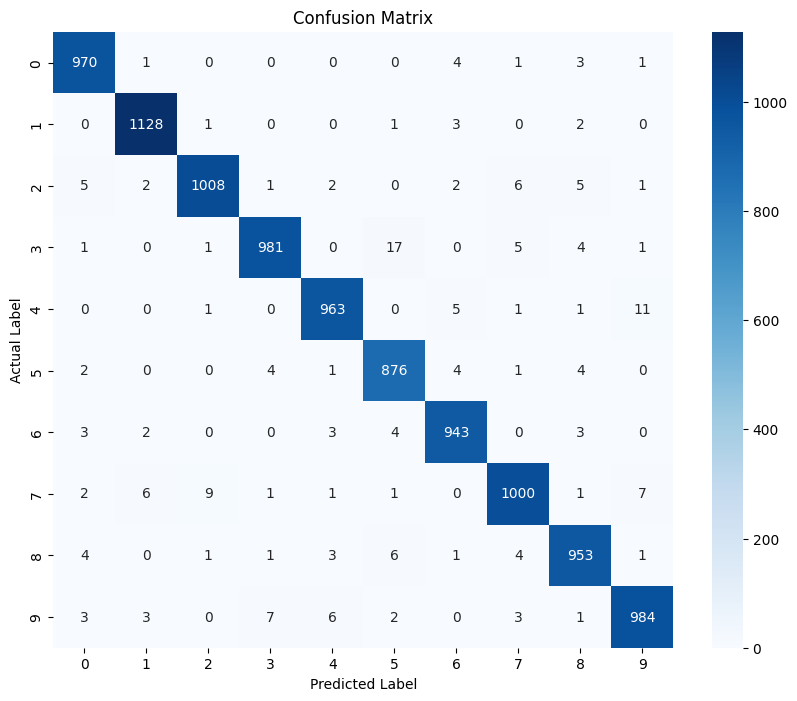

In [47]:
# Generate Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [48]:
# Generate Classification Report

print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        digits=4
    )
)

Classification Report:

              precision    recall  f1-score   support

           0     0.9798    0.9898    0.9848       980
           1     0.9877    0.9938    0.9908      1135
           2     0.9873    0.9767    0.9820      1032
           3     0.9859    0.9713    0.9786      1010
           4     0.9837    0.9807    0.9822       982
           5     0.9658    0.9821    0.9739       892
           6     0.9802    0.9843    0.9823       958
           7     0.9794    0.9728    0.9761      1028
           8     0.9754    0.9784    0.9769       974
           9     0.9781    0.9752    0.9767      1009

    accuracy                         0.9806     10000
   macro avg     0.9803    0.9805    0.9804     10000
weighted avg     0.9806    0.9806    0.9806     10000



## 18. Conclusion

In this project, we successfully developed a Deep Learning model to classify handwritten digits using the MNIST dataset.

We performed data preprocessing, including normalization and flattening, to prepare the images for training.

We built a Deep Neural Network with three hidden layers and applied Batch Normalization and Dropout to improve training stability and reduce overfitting.

The model was trained using the Adam optimizer and evaluated using test accuracy, test loss, confusion matrix, and classification report.

Training and validation accuracy and loss graphs were also used to analyze model performance.

Overall, this project demonstrates how Deep Learning can be used to recognize handwritten digits accurately using neural networks.